# Mide los planes de frontera frente a su evidencia

**Pregunta:** ¿Una diferencia positiva en el objetivo pareado significa que la política congelada produce planes útiles?

**Nivel 4.** Evidencia del método propuesto.

**Requisitos previos:** Lee primero las lecciones de mecánica de frontera y registros de entrenamiento. **Tiempo estimado:** 60 minutos.

## Objetivos

Este análisis guiado sigue la política congelada desde su prueba sintética reservada hasta los trece casos de producto declarados. Verificarás las identidades del entrenamiento y la evaluación, revisarás las filas de validación que seleccionaron los checkpoints, calcularás los intervalos predefinidos por grupos de semillas, compararás resultados de producto pareados e inspeccionarás dónde cae la cobertura. El notebook conserva cada caso parcial y fallido en su denominador. Utiliza solo registros agregados sanitizados: no incluye grafos generados, atributos de bloques, planes de instancias MineLib con licencia ni pesos del modelo. Al terminar podrás explicar por qué una diferencia media favorable puede coexistir con un plan mediano inutilizable, cómo cambia la interpretación al considerar el comparador y qué conclusiones pertenecen a este benchmark fijo, no a una población más amplia de minas.

## Preparación

Ejecuta desde la raíz del repositorio con los paquetes exactos indicados abajo. El notebook importa las mismas funciones PhaseFlow de resumen, validación de particiones y bootstrap por grupos de semillas que usa el flujo de evaluación. No entrena ni recarga el actor y no puede volver a abrir una partición de prueba. El conjunto compacto registra hashes de los recibos externos originales, commits congelados, identidades de partición y una fila por semilla sintética o caso de producto. Una ejecución nueva recalcula cada tabla y figura desde esas filas comprometidas. Si un digest o una identidad no coincide, detente y resuelve la procedencia antes de interpretar números; un resultado visualmente plausible no reemplaza un experimento pareado.

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2 torch==2.14.1
```

### Versiones del entorno

La siguiente celda informa las versiones instaladas antes de leer la evidencia.

In [1]:
# Informa los paquetes exactos antes de procesar evidencia.
import importlib.metadata

versions = {name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib", "torch")}
print(versions)


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2', 'torch': '2.14.1'}


### API y registros del producto

Importa funciones reutilizables de PhaseFlow para procedencia, resumen e incertidumbre; no las reimplementes.

In [2]:
# Localiza la raíz del repositorio e importa dependencias gráficas.
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside the PhaseFlow checkout.")
sys.path.insert(0, str(ROOT / "data-pipeline"))


### Carga y valida la evidencia congelada

La siguiente celda importa las API de análisis reutilizables, carga el agregado y valida el contrato de filas.

In [3]:
# Importa las API de análisis y valida el resumen comprometido.
from pipeline.model.frontier_evaluation import seed_clustered_interval, target_version
from pipeline.model.frontier_evidence import (
    summarize_case_rows,
    validate_frontier_diagnostic,
    validate_frontier_evaluation_summary,
)
from pipeline.model.frontier_policy import FrontierInstance, feasible_frontier, validate_schedule
from pipeline.model.frontier_ppo import (
    FrontierPolicyEnv,
    MaskedGraphActorCritic,
    select_ensemble_action,
    replay_frontier_ensemble,
)
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256

DATA = json.loads((ROOT / "notebooks/data/frontier-evaluation-summary.json").read_text(encoding="utf-8"))
SUMMARY_AUDIT = validate_frontier_evaluation_summary(DATA)
print(
    {
        "product_version": target_version(ROOT),
        "evaluation_commit": DATA["evaluation_source_commit"],
        "summary_audit": SUMMARY_AUDIT,
    }
)


{'product_version': '0.12.000', 'evaluation_commit': '4a106eae922c696856f4aff6f977d0f881d6c29a', 'summary_audit': {'synthetic_cases': 500, 'product_cases': 13, 'family': ['funnel'], 'empty_synthetic_schedules': 277, 'unique_product_case_ids': 13, 'declared_receipt_hashes': {'product_case_sha256': 'd023db6d67823ee189e944b16d0b9ed0e0aaba302d6754a127beb3ac91916bb2', 'synthetic_test_sha256': '2974b8ead9dfd81c0808e30fee5dfe3a2f148d5bdb984352a1b5880e48fd8f7d'}}}


## Datos

La prueba sintética contiene una observación por semilla de la familia funnel, separada de las familias de entrenamiento y validación. Los tamaños recorren el rango declarado de 32 a 8192 bloques. Cada fila incluye tamaño, estado del validador independiente, asignaciones, NPV normalizado, valor de TopoSort greedy, diferencia pareada y ambas coberturas. Los trece casos de producto registran NPV, brecha a la cota, tiempo, cobertura, estado, razón de falla y comparaciones pareadas. MineLib se limita a agregados por período: no se publican vectores por bloque. El resumen vincula hashes de checkpoints y recibos, commits, contrato, partición e índice. Son instancias sintéticas y benchmarks fijos, no datos de clientes ni de una operación minera.

Atribución: los casos gemelos sintéticos son generados por el equipo de PhaseFlow y el código del repositorio tiene licencia MIT. Los casos publicados pertenecen a MineLib (Espinoza, Goycoolea, Moreno y Newman, https://doi.org/10.1007/s10479-012-1258-3; catálogo https://mansci-web.uai.cl/minelib/). El texto de licencia de MineLib no está verificado; se trata el acceso como descarga académica sin permiso de redistribución. Aquí solo aparecen agregados permitidos.

## Método

Primero valida la partición congelada y el registro de selección de entrenamiento mediante la API del producto. Las 200 filas de validación ayudaron a seleccionar checkpoints; su resumen es un diagnóstico posterior a la selección. Después calcula la media, mediana, cobertura e intervalo bootstrap de la prueba por grupo de semillas. El estimador promedia filas repetidas dentro de una semilla antes de remuestrear semillas. En esta muestra reservada hay una fila por semilla, pero la API compartida conserva el protocolo si un manifiesto futuro incluye varias familias por semilla. No remuestrees bloques: comparten un grafo generado y no son unidades experimentales independientes. Conserva los ceros como resultados observados; eliminarlos respondería otra pregunta.


Para cada decisión, el actor puntúa bloques factibles y dos acciones de detención a partir de su embedding de grafo y el estado actual. Para miembro $k$, $\ell_{k,a}=f_{\theta_k}(h_a,s)$. El ensemble promedia cinco logits, $\bar\ell_a=K^{-1}\sum_{k=1}^{K}\ell_{k,a}$; la máscara reemplaza logits inadmisibles por $-\infty$ y elige $a^*=\arg\max_{a\in\mathcal{A}(s)}\bar\ell_a$. La hipótesis era que condicionar la puntuación por recursos residuales y estado mejora el orden fijo greedy cuando cambian las restricciones. El validador independiente revisa el plan final. La construcción preserva restricciones codificadas, pero no garantiza cobertura ni optimalidad.

Para cada caso de prueba, sea $Y_i$ el NPV normalizado de la política y $G_i$ el valor greedy en el mismo grafo. La diferencia pareada es $D_i=Y_i-G_i$. La media de $D_i$ y su intervalo bootstrap por grupos describen el contraste de valor bajo este generador. No miden por sí solos la utilidad. Compáralos con la distribución de $Y_i$, asignaciones y cobertura. Una política que devuelve cero es económicamente distinta de un plan de alta cobertura, aunque ambos satisfagan cada restricción estricta.

Para el caso de producto $c$ y comparador $m$, cuenta una victoria cuando $V_{frontera,c}>V_{m,c}$ para el mismo caso y objetivo. Informa el denominador junto al conteo y conserva los casos fallidos de política fuera del conteo pareado, pero dentro del denominador general de casos. Estos trece casos forman una suite fija, no una muestra aleatoria de una población objetivo; la fracción de victorias es descriptiva. Los comparadores pueden diferir en esfuerzo de cálculo; el tiempo, la brecha a la cota y la cobertura contextualizan el resultado, no forman un ranking único.

$$D_i=Y_i-G_i$$

$$\widehat{\Delta}=S^{-1}\sum_{s=1}^{S}\overline{D}_s$$

Cada semilla aporta un grupo; el estimador compartido promedia filas repetidas antes del remuestreo.

### Ejercicio acotado de mecánica de la política

Este DAG de cuatro bloques usa pesos inicializados al azar para demostrar el actor público, la máscara de acciones, la reproducción del ensemble y el validador independiente. No es un checkpoint entrenado, una observación de prueba, un resultado de benchmark ni evidencia de desempeño.

In [4]:
# Define un ejemplo determinista separado del registro congelado.
instance = FrontierInstance(
    values=np.array([7.0, 5.0, 4.0, 3.0]),
    resources=np.array([[1, 1], [1, 0], [0, 1], [1, 1]], dtype=float),
    predecessors=((), (0,), (0,), (1, 2)),
    capacities=np.array([[2, 2], [2, 2]], dtype=float),
    discount_rate=0.05,
)
node_features = np.array([[7, 1, 1], [5, 1, 0], [4, 0, 1], [3, 1, 1]], dtype=np.float32)
tonnage = np.array([10, 8, 7, 5], dtype=float)
print(
    {
        "blocks": len(instance.values),
        "periods": len(instance.capacities),
        "dag_edges": sum(map(len, instance.predecessors)),
    }
)


{'blocks': 4, 'periods': 2, 'dag_edges': 4}


La precedencia y la factibilidad de dos recursos provienen de la instancia canónica. Las dos acciones de detención son distintas de los índices de bloques. Inspecciona la máscara inicial antes de pedir al actor que puntúe el estado.

In [5]:
# Inspecciona las acciones legales en el estado inicial.
env = FrontierPolicyEnv(instance, node_features)
observation = env.observation()
engine_frontier = feasible_frontier(instance, (), 0)
legal_actions = np.flatnonzero(observation.admissible.numpy()).tolist()
print(
    {
        "legal_block_indices": [a for a in legal_actions if a < len(instance.values)],
        "independent_feasible_frontier": engine_frontier,
        "stop_period_index": len(instance.values),
        "stop_schedule_index": len(instance.values) + 1,
        "state_features": observation.state_features.tolist(),
    }
)


{'legal_block_indices': [0], 'independent_feasible_frontier': (0,), 'stop_period_index': 4, 'stop_schedule_index': 5, 'state_features': [0.0, 1.0, 1.0, 0.0, 0.25]}


El ensemble de dos integrantes ejecuta solo la ruta de inferencia. La inicialización fija hace reproducible esta lección; como los pesos no se entrenaron, sus decisiones no tienen interpretación científica ni operacional.

In [6]:
# Crea integrantes reproducibles solo para mecánica; no carga checkpoints.
import torch

torch.manual_seed(20261112)
models = [
    MaskedGraphActorCritic(node_feature_count=3, state_feature_count=env.state_feature_count)
    for _ in range(2)
]
for model in models:
    model.set_feature_normalizer([0, 0, 0], [1, 1, 1])
    model.eval()
print({"members": len(models), "trained_checkpoint_loaded": False, "device": "cpu"})


{'members': 2, 'trained_checkpoint_loaded': False, 'device': 'cpu'}


Primero promedia los logits de cada integrante y luego aplica la máscara para que las acciones inadmisibles reciban menos infinito. Las cabezas explícitas de detención siguen disponibles. El índice elegido demuestra mecánica determinista, no un plan preferible.

In [7]:
# Compara logits del ensemble con la máscara explícita de factibilidad.
with torch.no_grad():
    member_logits = torch.stack([model(observation, apply_mask=False)[0] for model in models])
    chosen_action, masked_logits = select_ensemble_action(models, observation)
print(
    {
        "chosen_action": chosen_action,
        "chosen_is_legal": bool(observation.admissible[chosen_action]),
        "stop_logits": masked_logits[-2:].tolist(),
        "masked_block_logits": masked_logits[:-2].tolist(),
    }
)


{'chosen_action': 5, 'chosen_is_legal': True, 'stop_logits': [-0.36709874868392944, 0.319482684135437], 'masked_block_logits': [-0.12575390934944153, -inf, -inf, -inf]}


Reproduce el plan mediante la función pública de inferencia. Avanza el plan, aplica cada máscara intermedia e invoca el validador separado al finalizar. Compara el objetivo con un cálculo nuevo sobre la instancia canónica.

In [8]:
# Reproduce el plan y recalcula de forma independiente el objetivo.
result = replay_frontier_ensemble(instance, node_features, models, tonnage=tonnage)
independent_npv = validate_schedule(instance, result.assignments)
assert np.isclose(result.npv, independent_npv)
print(
    {
        "assignments": [(row.block, row.period) for row in result.assignments],
        "stopped": result.stopped,
        "npv": result.npv,
        "validator_npv": independent_npv,
        "tonnage_coverage": result.tonnage_coverage,
        "positive_value_coverage": result.positive_value_coverage,
        "fixture_only": True,
        "performance_evidence": False,
    }
)


{'assignments': [], 'stopped': 'stop-schedule', 'npv': 0.0, 'validator_npv': 0.0, 'tonnage_coverage': 0.0, 'positive_value_coverage': 0.0, 'fixture_only': True, 'performance_evidence': False}


### Partición, selección e identidad del recibo

La siguiente celda comprueba pertenencia exacta a validación, commits de origen coincidentes y hashes de checkpoints seleccionados. Superar esta auditoría muestra que el diagnóstico pertenece a la partición declarada para selección; no lo convierte en evidencia de prueba.

In [9]:
# Concilia el diagnóstico de selección con el manifiesto y recibo de entrenamiento.
RECORDS = ROOT / "docs/design/features/learned-frontier/records"
manifest = json.loads((ROOT / "docs/design/features/learned-frontier/split-manifest.json").read_text())[
    "manifest"
]
training = json.loads((RECORDS / "training-summary.json").read_text())
diagnostic = json.loads((RECORDS / "validation-diagnostic.json").read_text())
audit = validate_frontier_diagnostic(manifest, training, diagnostic)
rebuilt = build_split_manifest(manifest["product_case_ids"])
print(
    {
        "validation_rows": audit["validation_cases"],
        "members": len(audit["members"]),
        "median_npv": audit["summary"]["median_npv"],
        "split_rebuilt": manifest_sha256(rebuilt) == manifest_sha256(manifest),
    }
)


{'validation_rows': 200, 'members': 5, 'median_npv': 0.0, 'split_rebuilt': True}


### Resúmenes de prueba e incertidumbre por grupos

Convierte cada fila sintética al contrato esperado por `summarize_case_rows`. La API conserva planes vacíos y verifica IDs de semilla únicos, NPV finito, cobertura acotada y asignaciones no negativas. La función de intervalo aplica la semilla y cantidad de réplicas congeladas a NPV y a la diferencia pareada.

In [10]:
# Recalcula los resúmenes y ambos intervalos predeclarados por grupos de semillas.
synthetic = DATA["synthetic_cases"]
summary_rows = [
    {
        "seed": r["seed"],
        "normalized_npv": r["normalized_npv"],
        "positive_value_coverage": r["positive_value_coverage"],
        "assigned_blocks": r["assignments"],
    }
    for r in synthetic
]
policy_summary = summarize_case_rows(summary_rows)
npv_ci = seed_clustered_interval(synthetic, metric="normalized_npv")
paired_ci = seed_clustered_interval(synthetic, metric="frontier_minus_classical_normalized_npv")
paired = np.asarray([r["frontier_minus_classical_normalized_npv"] for r in synthetic], dtype=float)
print(
    {
        "policy": policy_summary,
        "mean_paired_difference": float(paired.mean()),
        "median_paired_difference": float(np.median(paired)),
        "npv_interval": npv_ci,
        "paired_interval": paired_ci,
    }
)


{'policy': {'cases': 500, 'nonempty_fraction': 0.446, 'mean_assigned_blocks': 1.766, 'mean_npv': 0.000846990568954812, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0010244701234927275, 'maximum_npv': 0.07325625661022492}, 'mean_paired_difference': 0.186183414847193, 'median_paired_difference': 0.1676677565044022, 'npv_interval': {'metric': 'normalized_npv', 'unit': 'seed-cluster', 'clusters': 500, 'replicates': 10000, 'rng_seed': 5519, 'confidence_level': 0.95, 'lower': 0.0005250058699371804, 'upper': 0.0012700406707918538}, 'paired_interval': {'metric': 'frontier_minus_classical_normalized_npv', 'unit': 'seed-cluster', 'clusters': 500, 'replicates': 10000, 'rng_seed': 5519, 'confidence_level': 0.95, 'lower': 0.16181947421466503, 'upper': 0.20979946603435803}}


### Interpretación de la figura pareada

El panel izquierdo muestra distribuciones de NPV normalizado de política y greedy en los mismos casos. El derecho grafica la diferencia pareada y su intervalo por grupos de semillas frente a cero. El intervalo puede excluir cero aunque el plan típico esté vacío; revisa la masa en cero y la cobertura antes de llamar útil al contraste.

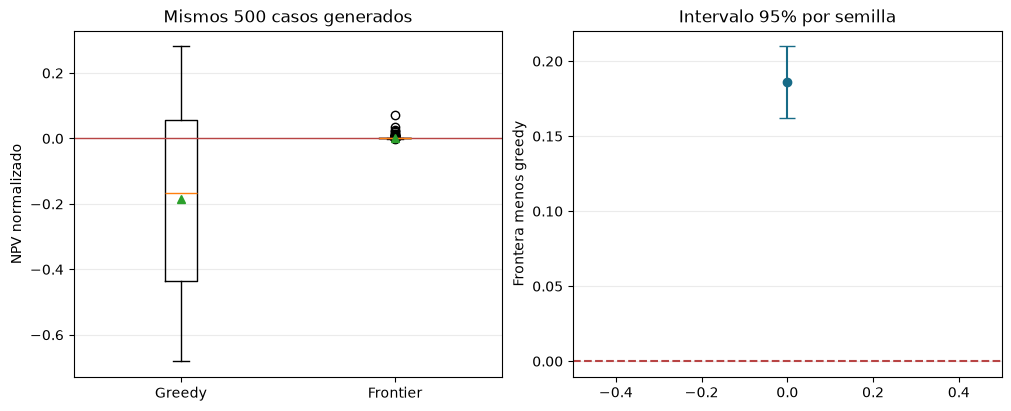

In [11]:
# Grafica valores pareados y su intervalo congelado por grupos.
policy_npv = np.asarray([r["normalized_npv"] for r in synthetic])
greedy_npv = np.asarray([r["classical_normalized_npv"] for r in synthetic])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].boxplot([greedy_npv, policy_npv], tick_labels=["Greedy", "Frontier"], showmeans=True)
axes[0].axhline(0, color="#B84444", linewidth=1)
axes[0].set(ylabel="NPV normalizado", title="Mismos 500 casos generados")
axes[1].errorbar(
    [0],
    [paired.mean()],
    yerr=[[paired.mean() - paired_ci["lower"]], [paired_ci["upper"] - paired.mean()]],
    fmt="o",
    capsize=6,
    color="#176B87",
)
axes[1].axhline(0, color="#B84444", linestyle="--")
axes[1].set(xlim=(-0.5, 0.5), ylabel="Frontera menos greedy", title="Intervalo 95% por semilla")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()


El diagrama confirma la masa de la política en cero y muestra la cola negativa de greedy. El intervalo pareado es positivo, pero su interpretación queda limitada por la cobertura casi nula de la política. Es un contraste del objetivo bajo un generador, no una afirmación de producción ni seguridad en terreno.

## Comparación

El comparador greedy pareado responde si la política mejora el mismo objetivo de valor en el mismo grafo generado. Una diferencia media positiva puede aparecer cuando un método devuelve cero y el otro un plan de valor negativo. La mediana del NPV de la política y su cobertura revelan este patrón: la media de prueba es positiva, pero el resultado típico está vacío. La comparación de producto agrega métodos con presupuestos de búsqueda distintos. Sus resultados pareados muestran dónde pierde la frontera aunque se mantenga factible. Lee cada conteo junto con su denominador; no combines NPV heterogéneos de casos distintos en un único porcentaje de mejora.

In [12]:
# Cuenta resultados de producto pareados y conserva todas las fallas.
product = DATA["product_cases"]
methods = sorted({m["method"] for row in product for m in row["paired_baseline_methods"]})
comparison = []
for name in methods:
    values = [
        m["frontier_minus_baseline_npv"]
        for row in product
        for m in row["paired_baseline_methods"]
        if m["method"] == name
    ]
    comparison.append(
        {
            "method": name,
            "wins": sum(v > 0 for v in values),
            "paired_cases": len(values),
            "losses": sum(v < 0 for v in values),
        }
    )
failures = [{"case": r["case_id"], "reason": r["failure_reason"]} for r in product if r["status"] == "failed"]
print(
    {
        "statuses": {
            s: sum(r["status"] == s for r in product)
            for s in ("complete", "partial", "failed", "unavailable")
        },
        "comparisons": comparison,
        "failures": failures,
    }
)


{'statuses': {'complete': 0, 'partial': 11, 'failed': 2, 'unavailable': 0}, 'comparisons': [{'method': 'bench-by-bench', 'wins': 11, 'paired_cases': 11, 'losses': 0}, {'method': 'cpitD-local-search', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'exts-two-resource', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'learned-expected-time', 'wins': 2, 'paired_cases': 11, 'losses': 9}, {'method': 'nested-shells', 'wins': 9, 'paired_cases': 11, 'losses': 2}, {'method': 'shift-local-search', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'sliding-window', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'toposort-expected', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'toposort-gershon', 'wins': 8, 'paired_cases': 11, 'losses': 3}, {'method': 'toposort-greedy', 'wins': 9, 'paired_cases': 11, 'losses': 2}], 'failures': [{'case': 'ctrl-degenerate', 'reason': 'ValueError: frontier policy currently requires the declared two-resource CPIT contract

### Lectura de la comparación de producto

Cada barra utiliza la cantidad de casos pareados exitosos, no los trece. Las dos entradas fallidas permanecen en el estado y no se convierten silenciosamente en cero victorias. La política supera a greedy en la mayoría de casos soportados, mientras expected-time exacto y varios métodos de búsqueda local la superan en los once. No se muestra intervalo porque esta suite fija no es una muestra aleatoria.

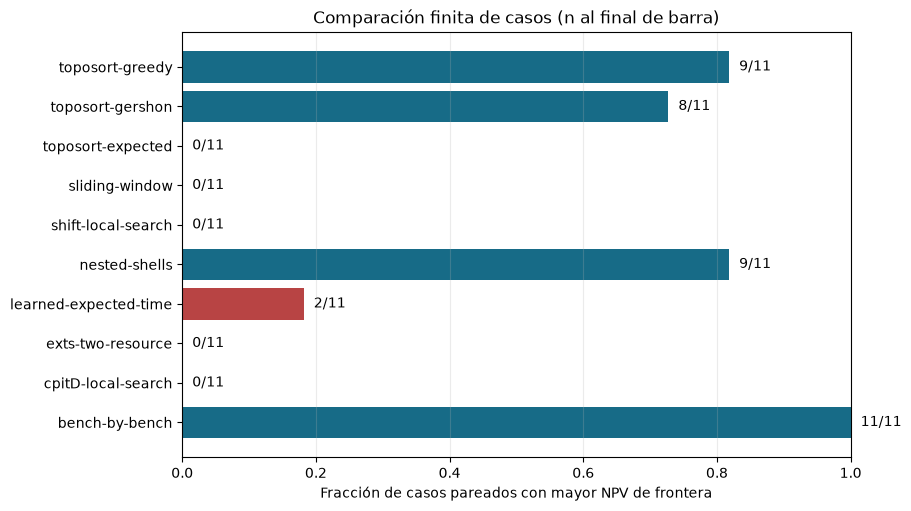

In [13]:
# Muestra conteos de victorias y denominadores de la suite fija.
labels = [row["method"] for row in comparison]
rates = [row["wins"] / row["paired_cases"] for row in comparison]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
y = np.arange(len(labels))
ax.barh(y, rates, color=["#176B87" if value >= 0.5 else "#B84444" for value in rates])
ax.set(
    yticks=y,
    yticklabels=labels,
    xlim=(0, 1),
    xlabel="Fracción de casos pareados con mayor NPV de frontera",
    title="Comparación finita de casos (n al final de barra)",
)
for i, row in enumerate(comparison):
    ax.text(rates[i] + 0.015, i, f"{row['wins']}/{row['paired_cases']}", va="center")
ax.grid(axis="x", alpha=0.25)
plt.show()


La comparación separa el conteo favorable frente a greedy de las pérdidas frente a búsquedas más fuertes. Sus denominadores cubren los once casos soportados. Como cambian la economía de los casos y el esfuerzo del solver, la figura no es un ranking universal y el conteo no mide cuánto vale una victoria.

## Evidencia

La prueba sintética produce 500 planes factibles parciales, no 500 planes completos. Su NPV normalizado medio es 0.00084699 y la mediana es cero. El intervalo predefinido del 95% por grupos de semillas para la media es [0.00052501, 0.00127004]. La diferencia media pareada frente a greedy es 0.18618341, con intervalo [0.16181947, 0.20979947]. El cálculo sobre las asignaciones identifica 277 planes vacíos de 500 (55,4%); las medianas de cobertura de tonelaje y valor son cero. Por ello, bajo esta política congelada y este generador, el resultado es negativo para la cobertura práctica pese al contraste favorable que usa solo valor.

La evaluación de producto produce once planes factibles parciales y dos fallas. `ctrl-degenerate` usa un recurso, mientras el adaptador actual exige la entrada declarada de dos recursos; `zuck-small-declared` no declara un vector de ley con fuente trazable. Entre las once filas pareadas, las victorias son 11/11 frente a bench-by-bench, 9/11 frente a nested-shells, 9/11 frente a greedy, 8/11 frente a Gershon y 2/11 frente a expected-time aprendido. La política registra 0/11 frente a ordenamiento expected-time exacto, sliding-window, shift-local-search y búsqueda local C-PIT[D]. Estos resultados describen este conjunto finito y no estiman una tasa poblacional.

Plot key: number, case ID, tonnage coverage, NPV / certified bound
1 ctrl-abundant 0.917 0.964
2 kd-declared 0.659 0.803
3 newman1-published 0.995 0.942
4 regime-high-discount 0.368 0.862
5 regime-mill-bound 0.261 0.78
6 regime-mining-bound 0.3 0.728
7 twin-core-halo 0.356 0.133
8 twin-layered 0.452 0.859
9 twin-porphyry-l 0.339 0.849
10 twin-porphyry-s 0.368 0.893
11 twin-vein 0.336 0.784


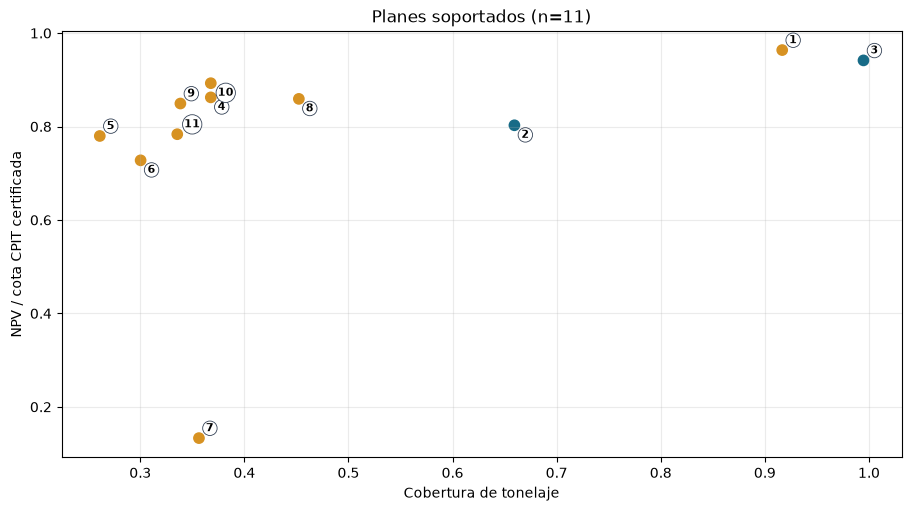

In [14]:
# Grafica NPV relativo a la cota frente a cobertura y marca fallas sin inventar puntajes.
supported = sorted(
    (r for r in product if r["status"] in ("complete", "partial") and r["certified_bound"]),
    key=lambda row: row["case_id"],
)
case_key = {r["case_id"]: i + 1 for i, r in enumerate(supported)}
print("Plot key: number, case ID, tonnage coverage, NPV / certified bound")
for r in supported:
    print(
        case_key[r["case_id"]],
        r["case_id"],
        round(r["tonnage_coverage"], 3),
        round(r["npv"] / r["certified_bound"], 3),
    )
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
x = [r["tonnage_coverage"] for r in supported]
y = [r["npv"] / r["certified_bound"] for r in supported]
ax.scatter(x, y, c=["#176B87" if r["source"] == "licensed-minelib" else "#D79222" for r in supported], s=55)
for i, r in enumerate(supported, start=1):
    ax.annotate(
        str(i),
        (r["tonnage_coverage"], r["npv"] / r["certified_bound"]),
        xytext=(5, 5 if i % 2 else -9),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        bbox={"boxstyle": "circle,pad=0.15", "facecolor": "white", "edgecolor": "#334155", "linewidth": 0.6},
    )
ax.set(xlabel="Cobertura de tonelaje", ylabel="NPV / cota CPIT certificada", title="Planes soportados (n=11)")
ax.grid(alpha=0.25)
plt.show()


La dispersión usa marcadores numerados vinculados con la clave impresa para mantener legibles las observaciones agrupadas sin superponer IDs largos. Contiene solo once casos puntuados; las entradas fallidas no tienen coordenadas y no se dibujan en el origen. La razón respecto de la cota y la cobertura resumen dimensiones distintas y omiten restricciones operacionales.

### Sensibilidad y límites

Los 500 grafos reservados pertenecen a la familia funnel; esta prueba no estima diferencias entre familias. El código divide el rango de tamaño observado en cuatro cuartiles empíricos e informa cantidad de casos, tamaño mínimo y máximo, NPV medio, cobertura media de valor positivo y fracción de planes vacíos. Es una descripción posterior al acceso para preguntar si el resultado cambia con el tamaño, no una prueba confirmatoria por subgrupo. La política y el generador quedan congelados; estos cortes no autorizan ajustar un umbral y reutilizar la misma muestra como confirmación.

Las tres figuras responden preguntas distintas. La primera grafica valores pareados de prueba y resalta la masa de planes vacíos. Muestra si la diferencia media surge de un desplazamiento amplio o de la cola del baseline; no implica desempeño en terreno. La segunda compara conteos de victorias por caso y hace visible el denominador. Excluye del pareo solo casos donde la política falló antes de producir un plan comparable, pero esas fallas permanecen en la tabla total de trece. La tercera relaciona NPV relativo a la cota con cobertura para cada caso de producto soportado. La fracción respecto de la cota da una escala vertical común a montos distintos; no vuelve idénticas sus economías. Los casos fallidos se marcan aparte porque no existe un puntaje de desempeño medido.

La prueba completada de la familia funnel no incluye una ablación de solo detención, eliminación de componentes ni un segundo ensemble congelado. No identifica qué componente arquitectónico causó la abstención. El diseño de entrenamiento usa otras familias, pero los resultados reservados contienen solo grafos funnel y reglas económicas y de recursos simplificadas. Los cuartiles de tamaño no sustituyen un estudio planificado de transferencia entre familias. No representa incertidumbre de sondajes, conciliación geotécnica, despacho de flota, flujo de acopios, variabilidad de planta ni restricciones de operadores. Los trece casos declarados agregan contexto matemático, pero dos no están soportados y los restantes forman un conjunto finito. Un plan que pasa el validador codificado no es un plan operacional. Cualquier cambio de modelo, atributos o entrenamiento después de observar estos resultados requiere un protocolo nuevo y una prueba intacta.

In [15]:
# Compara la política congelada por cuartiles empíricos del tamaño, no por familia.
sizes = np.asarray([r["size"] for r in synthetic], dtype=int)
cutpoints = np.quantile(sizes, [0.25, 0.50, 0.75])
size_groups = np.digitize(sizes, cutpoints, right=True)
size_rows = []
for group in range(4):
    rows = [r for r, label in zip(synthetic, size_groups, strict=True) if label == group]
    size_rows.append(
        {
            "quartile": group + 1,
            "cases": len(rows),
            "size_min": min(r["size"] for r in rows),
            "size_max": max(r["size"] for r in rows),
            "mean_npv": float(np.mean([r["normalized_npv"] for r in rows])),
            "mean_value_coverage": float(np.mean([r["positive_value_coverage"] for r in rows])),
            "empty_fraction": float(np.mean([r["assignments"] == 0 for r in rows])),
        }
    )
print({"families": sorted({r["family"] for r in synthetic}), "size_quartiles": size_rows})


{'families': ['funnel'], 'size_quartiles': [{'quartile': 1, 'cases': 125, 'size_min': 32, 'size_max': 2059, 'mean_npv': 0.002622018040063465, 'mean_value_coverage': 0.006589691531303815, 'empty_fraction': 0.536}, {'quartile': 2, 'cases': 125, 'size_min': 2076, 'size_max': 4103, 'mean_npv': 0.0002885324032298698, 'mean_value_coverage': 0.0007835866707489523, 'empty_fraction': 0.584}, {'quartile': 3, 'cases': 125, 'size_min': 4120, 'size_max': 6147, 'mean_npv': 0.00029839124471916795, 'mean_value_coverage': 0.0006836100845516171, 'empty_fraction': 0.512}, {'quartile': 4, 'cases': 125, 'size_min': 6164, 'size_max': 8192, 'mean_npv': 0.00017902058780674553, 'mean_value_coverage': 0.0003888817448277976, 'empty_fraction': 0.584}]}


Cada cuartil informa el tamaño del grupo y sus resúmenes. El gráfico separado mantiene visibles los planes vacíos junto con el valor medio.

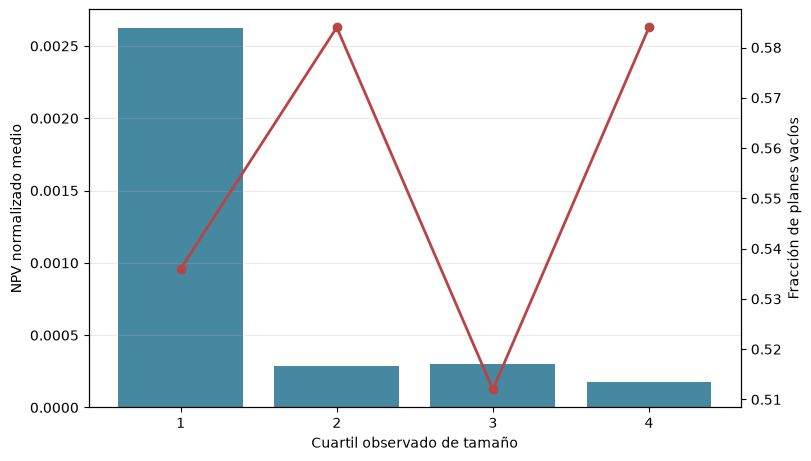

In [16]:
# Grafica medias por cuartil y fracciones de planes vacíos en escalas separadas.
quartiles = [row["quartile"] for row in size_rows]
mean_npv = [row["mean_npv"] for row in size_rows]
empty_fraction = [row["empty_fraction"] for row in size_rows]
fig, left = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
left.bar(quartiles, mean_npv, color="#176B87", alpha=0.8)
left.set(xlabel="Cuartil observado de tamaño", ylabel="NPV normalizado medio")
right = left.twinx()
right.plot(quartiles, empty_fraction, color="#B84444", marker="o", linewidth=2)
right.set_ylabel("Fracción de planes vacíos")
left.set_xticks(quartiles)
left.grid(axis="y", alpha=0.25)
plt.show()


Los cuartiles de tamaño exponen heterogeneidad posterior al acceso sin cambiar la política congelada. Un resultado débil por tamaño es descriptivo y no autoriza reajustar la política con estos casos. El intervalo sigue agrupado por semilla; estos cortes no son pruebas confirmatorias nuevas.

### Usa el análisis con tus propios datos

Comienza con una fila inmutable por semilla sintética independiente o caso de benchmark. Conserva un identificador opaco, familia de origen, tamaño del grafo, partición, estado del método, unidades del objetivo, conteo de asignaciones, ambas fracciones de cobertura, objetivo de referencia, digest de fuente, digest del contrato de atributos, digest del checkpoint seleccionado y versión del evaluador. Registra una razón cuando la política no produce un plan. Nunca codifiques una falla como NPV cero: cero es un plan vacío medido, mientras que una falla significa que no hubo objetivo disponible. Mantén identificadores de bloque restringidos y asignaciones por período de MineLib fuera del resumen público.

Comienza con una fila inmutable por semilla sintética independiente o caso de benchmark. Conserva un identificador opaco, familia de origen, tamaño del grafo, partición, estado del método, unidades del objetivo, conteo de asignaciones, ambas fracciones de cobertura, objetivo de referencia, digest de fuente, digest del contrato de atributos, digest del checkpoint seleccionado y versión del evaluador. Registra una razón cuando la política no produce un plan. Nunca codifiques una falla como NPV cero: cero es un plan vacío medido, mientras que una falla significa que no hubo objetivo disponible. Mantén los identificadores de bloque restringidos y las asignaciones por período de MineLib fuera del resumen público.

La API `summarize_case_rows` recibe filas con `seed`, `normalized_npv`, `positive_value_coverage` y `assigned_blocks`. Rechaza campos ausentes, semillas duplicadas, métricas no finitas, cobertura fuera de rango y asignaciones negativas. La API `seed_clustered_interval` recibe todas las filas, nombre de métrica, cantidad de réplicas y semilla RNG; conserva solo resultados completos o parciales factibles con semillas válidas y calcula el bootstrap declarado. En un experimento nuevo, congela esos parámetros antes de abrir la prueba, conserva todas las fallas en el recibo e informa cuántas filas entraron en cada contraste pareado.

Antes de calcular resúmenes, reconcilia IDs de casos con el manifiesto congelado y confirma que los métodos pareados compartan digest de instancia y objetivo. Recalcula factibilidad y NPV desde el plan canónico en un entorno controlado antes de exportar agregados. Compara conteos de estado con las filas retenidas, verifica hashes de recibos y confirma que entradas con licencia no contengan vectores por bloque. Usa gráficos descriptivos para casos de benchmark fijos y reserva intervalos de confianza para la unidad muestral independiente del protocolo. Esta lección demuestra el análisis del estudio congelado; no autoriza un protocolo de evaluación nuevo ni vuelve comparable un conjunto aportado por el usuario sin igualar unidades y restricciones.

In [17]:
# Define un ejemplo compacto con resultados vacíos y negativos medidos.
own_fields = ("seed", "status", "feasible", "normalized_npv", "positive_value_coverage", "assigned_blocks")
own_values = [
    (8101, "partial", True, 0.04, 0.12, 3),
    (8102, "partial", True, 0.00, 0.00, 0),
    (8103, "complete", True, 0.09, 0.35, 7),
    (8104, "partial", True, -0.01, 0.02, 1),
]
own_rows = [dict(zip(own_fields, values, strict=True)) for values in own_values]


Procesa las cuatro filas con las mismas API de resumen y grupos de semillas usadas arriba. El intervalo solo demuestra la mecánica: cuatro observaciones no sustentan una estimación científica útil.

In [18]:
# Resume el ejemplo y calcula su intervalo declarado por grupos.
own_summary = summarize_case_rows(own_rows)
own_interval = seed_clustered_interval(own_rows, metric="normalized_npv", replicates=2000, seed=118)
print({"illustrative_rows": len(own_rows), "summary": own_summary, "interval": own_interval})


{'illustrative_rows': 4, 'summary': {'cases': 4, 'nonempty_fraction': 0.75, 'mean_assigned_blocks': 2.75, 'mean_npv': 0.03, 'median_npv': 0.02, 'median_value_coverage': 0.06999999999999999, 'minimum_npv': -0.01, 'maximum_npv': 0.09}, 'interval': {'metric': 'normalized_npv', 'unit': 'seed-cluster', 'clusters': 4, 'replicates': 2000, 'rng_seed': 118, 'confidence_level': 0.95, 'lower': -0.005, 'upper': 0.0675}}


Este ejemplo independiente de cuatro filas demuestra el contrato del llamador; no es una parte de la prueba abierta. Para datos reales, valida cada fila contra su manifiesto y procedencia congelados, conserva casos fallidos y no disponibles en el recibo y reserva grupos intactos para confirmación. Cuatro filas son insuficientes para inferencia científica.

## Resultados

**Respuesta:** No. La media pareada positiva no demuestra planes útiles: 277 de 500 están vacíos, el NPV y la cobertura medianos son cero, y varios comparadores más fuertes ganan los once casos pareados.

El análisis responde la pregunta de forma acotada. La diferencia pareada es positiva, pero el plan sintético típico asigna cero bloques y tiene cobertura de valor cero. En los casos de producto, la política vence al constructor greedy en nueve de once filas soportadas y pierde en todos los casos frente a varios baselines más fuertes de ordenamiento y búsqueda local. Dos entradas fallan de forma cerrada. La factibilidad es una propiedad del software; la cobertura útil y el valor comparativo son propiedades empíricas, y aquí apuntan en otra dirección.

Las figuras no establecen causalidad de ningún componente, robustez a otro generador ni transferencia a una mina. El intervalo bootstrap cubre variación entre semillas en este diseño sintético congelado. Los conteos de producto resumen la suite nombrada de trece casos y no tienen interpretación muestral. El tiempo mide inferencia en esta configuración de máquina, no el costo total de entrenamiento ni una velocidad universal. Estos límites forman parte del resultado, no son notas al pie opcionales al presentar los números.

## Resumen

Un análisis defendible conserva el denominador completo, calcula incertidumbre al nivel de semilla e interpreta el objetivo pareado junto con asignaciones y cobertura. La diferencia favorable frente a greedy coexiste con NPV y cobertura medianos iguales a cero porque la política suele abstenerse. La comparación de producto muestra que la factibilidad no evita pérdidas frente a métodos con búsqueda más fuerte. Conserva las dos entradas fallidas, distingue la muestra completada de los intentos consumidos y no transformes un benchmark finito en una afirmación general. El resultado actual es un diagnóstico reproducible de baja cobertura; la aplicación sigue cerrada a esta reproducción hasta terminar una nueva cocción completa y revisión de publicación.

## Referencias

1. Teichteil-Königsbuch et al., políticas con redes de grafos para programación con recursos limitados, ICAPS 2023, https://doi.org/10.1609/icaps.v33i1.27244
2. Lambert et al., tutorial de formulaciones de secuenciación de bloques a cielo abierto, https://doi.org/10.1287/inte.2013.0731
3. Schulman et al., optimización de política proximal, https://arxiv.org/abs/1707.06347
4. Código fuente, contratos y evaluación de PhaseFlow, https://github.com/fsantibanezleal/CAOS_PhaseFlow